In [1]:
import warnings
warnings.filterwarnings("ignore")

# Data Exploration

In [2]:
from datasets import load_dataset

dataset = load_dataset("Bingsu/Human_Action_Recognition", split="train")
dataset = dataset.shuffle(seed=42)
dataset = dataset.train_test_split(test_size=0.2, seed=42)

In [3]:
dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'labels'],
        num_rows: 10080
    })
    test: Dataset({
        features: ['image', 'labels'],
        num_rows: 2520
    })
})

In [4]:
dataset["train"][0]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=264x191>,
 'labels': 0}

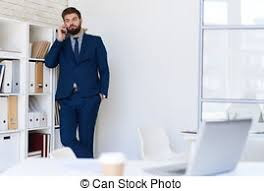

In [5]:
dataset["train"][0]["image"]

Getting all possible labels to create the according dictionaries for the models

In [6]:
labels = dataset["train"].features["labels"].names
labels

['calling',
 'clapping',
 'cycling',
 'dancing',
 'drinking',
 'eating',
 'fighting',
 'hugging',
 'laughing',
 'listening_to_music',
 'running',
 'sitting',
 'sleeping',
 'texting',
 'using_laptop']

In [7]:
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for i, label in enumerate(labels)}

# Image Preprocessing

Used Vision Transformer is a base model used on 16x16 patches with image size of 224, trained with image net dataset with 21000 classes

In [8]:
from transformers import AutoImageProcessor

model_ckpt = "google/vit-base-patch16-224-in21k"

This is the preprocessing script containing normalization, cropping and conversion to tensor

In [9]:
from torchvision.transforms import RandomResizedCrop, Compose, Normalize, ToTensor

image_processor = AutoImageProcessor.from_pretrained(model_ckpt, use_fast=True)
normalize = Normalize(mean=image_processor.image_mean, std=image_processor.image_std)

size = (image_processor.size['shortest_edge'] if 'shortest_edge' in image_processor.size 
        else (image_processor.size['height'], image_processor.size['width']))

_transforms = Compose([RandomResizedCrop(size), ToTensor(), normalize])

def transforms(batch):
    batch['pixel_values'] = [_transforms(img.convert('RGB')) for img in batch['image']]

    del batch['image']

    return batch

To every vision model, there is an according image processor used to convert the input images to a proper format for the model.\
It comes with some config values that can be retrieved to manipulate images correctly:

In [10]:
image_processor

ViTImageProcessorFast {
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessorFast",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}

Do the transformations with the with_transform() method, pretty similar to the map() function.

In [11]:
dataset = dataset.with_transform(transforms)

# Model Preparation

In [12]:
import evaluate
import numpy as np

accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return accuracy.compute(predictions=predictions, references=labels)

Creation of ViT model. The ViT also gets a new trainable classification layer to produce the prediction in correct format.

In [13]:
from transformers import AutoModelForImageClassification, TrainingArguments, Trainer
import torch

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

model = AutoModelForImageClassification.from_pretrained(
    model_ckpt,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
    # ignore_mismatched_sizes=True,
).to(device)


Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [14]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {trainable_params:,}")

Trainable parameters: 85,810,191


# Training

Set all params for the training.

In [17]:
args = TrainingArguments(
    output_dir="train_dir",
    remove_unused_columns=False,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=1,
    num_train_epochs=2,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["test"],
    compute_metrics=compute_metrics,
    tokenizer=image_processor,
)

Fix: **Runtime Error: view size is not compatible with input tensor's size and stride** during training by\
by installing the following versions: torch-2.4.0 torchvision-0.19.0

In [18]:
trainer.train()

  0%|          | 0/1260 [00:00<?, ?it/s]

{'loss': 2.0013, 'grad_norm': 4.922664642333984, 'learning_rate': 1.2063492063492064e-05, 'epoch': 0.79}


  0%|          | 0/158 [00:00<?, ?it/s]

{'eval_loss': 1.428281545639038, 'eval_accuracy': 0.7174603174603175, 'eval_runtime': 31.4555, 'eval_samples_per_second': 80.113, 'eval_steps_per_second': 5.023, 'epoch': 1.0}
{'loss': 1.3547, 'grad_norm': 5.5218915939331055, 'learning_rate': 4.126984126984127e-06, 'epoch': 1.59}


  0%|          | 0/158 [00:00<?, ?it/s]

{'eval_loss': 1.2699850797653198, 'eval_accuracy': 0.725, 'eval_runtime': 30.9563, 'eval_samples_per_second': 81.405, 'eval_steps_per_second': 5.104, 'epoch': 2.0}
{'train_runtime': 831.1083, 'train_samples_per_second': 24.257, 'train_steps_per_second': 1.516, 'train_loss': 1.5872379847935267, 'epoch': 2.0}


TrainOutput(global_step=1260, training_loss=1.5872379847935267, metrics={'train_runtime': 831.1083, 'train_samples_per_second': 24.257, 'train_steps_per_second': 1.516, 'total_flos': 1.562420534675374e+18, 'train_loss': 1.5872379847935267, 'epoch': 2.0})

In [19]:
trainer.evaluate()

  0%|          | 0/158 [00:00<?, ?it/s]

{'eval_loss': 1.2682017087936401,
 'eval_accuracy': 0.7285714285714285,
 'eval_runtime': 30.9326,
 'eval_samples_per_second': 81.467,
 'eval_steps_per_second': 5.108,
 'epoch': 2.0}

In [20]:
trainer.save_model("vit-human-pose-classification")

# Model Evaluation

In [21]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

Using the testset to get prediction logits

In [22]:
logits = trainer.predict(dataset["test"])

  0%|          | 0/158 [00:00<?, ?it/s]

There are 2520 examples and 15 possible classes

In [25]:
logits.predictions.shape

(2520, 15)

Get the predicted class via argmax

In [32]:
y_pred = np.argmax(logits.predictions, axis=-1)
print(len(y_pred))

2520


Create a list of labels from the test labels. The list has the same len like the predictions.

In [33]:
y_true = [x["labels"] for x in dataset["test"]]
print(len(y_true))

2520


Use the classification_report func to get a report on how good / bad the predictions were.

In [34]:
print(classification_report(y_true, y_pred, target_names=labels))

                    precision    recall  f1-score   support

           calling       0.72      0.57      0.64       196
          clapping       0.71      0.73      0.72       175
           cycling       0.92      0.95      0.93       137
           dancing       0.68      0.77      0.73       149
          drinking       0.72      0.80      0.76       153
            eating       0.85      0.80      0.82       166
          fighting       0.71      0.78      0.74       162
           hugging       0.73      0.77      0.75       181
          laughing       0.69      0.76      0.73       167
listening_to_music       0.64      0.69      0.66       145
           running       0.89      0.81      0.85       206
           sitting       0.65      0.55      0.60       172
          sleeping       0.86      0.83      0.85       193
           texting       0.68      0.51      0.58       173
      using_laptop       0.53      0.68      0.59       145

          accuracy                    

Create a confusion matrix showing strengths, weaknesses and overall performances.

In [35]:
cm = confusion_matrix(y_true, y_pred)

Confusion matrix shows that model is actually good at predicting poses. Still, it makes some errors sometimes.\
A good example is that dancing and fighting is misinterpreted pretty often. This is probably because the moves of both activities look pretty similar (e. g. using the arms and legs for both).

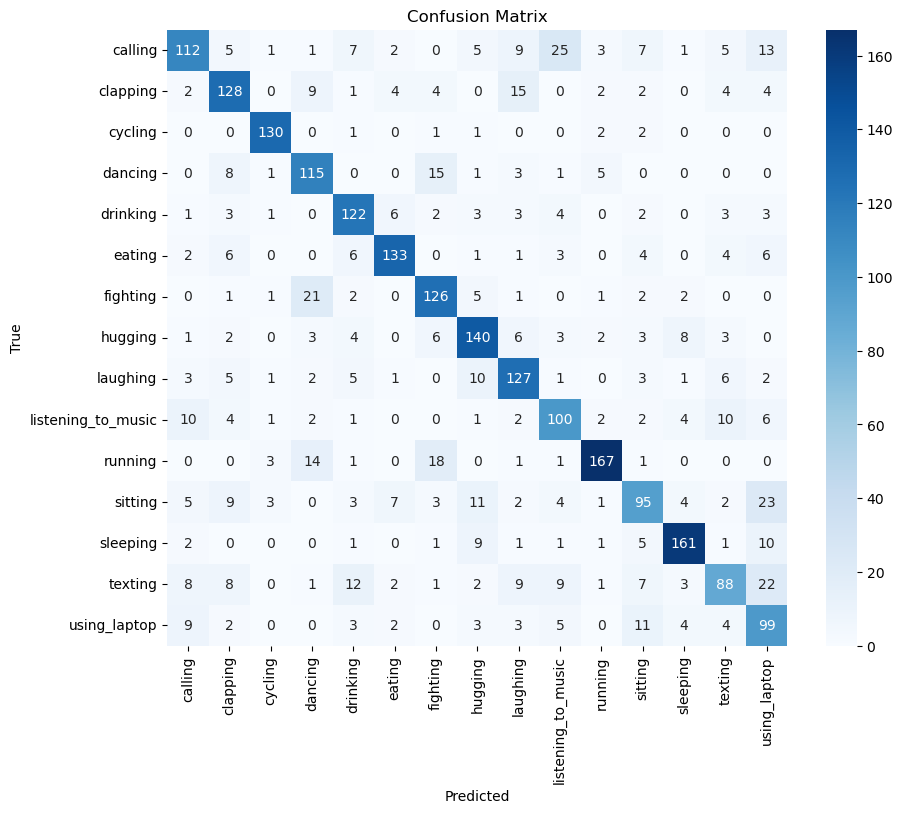

In [38]:
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Prediction on real image

Setting up a pipeline for prediction

In [40]:
from transformers import pipeline
from transformers import AutoImageProcessor

model_ckpt = "vit-human-pose-classification"
image_processor = AutoImageProcessor.from_pretrained(model_ckpt)

human_pose_classifier = pipeline("image-classification", model="vit-human-pose-classification", image_processor=image_processor, device=device)

This image (showing a **sitting** woman) will be fed into the model

<img src="https://images.pexels.com/photos/1755385/pexels-photo-1755385.jpeg" width="300"/>

Model successfully predicts the person **sitting**.

In [42]:
url = "https://images.pexels.com/photos/1755385/pexels-photo-1755385.jpeg"
output = human_pose_classifier(url)
output

[{'label': 'sitting', 'score': 0.8422577381134033},
 {'label': 'using_laptop', 'score': 0.8143529891967773},
 {'label': 'sleeping', 'score': 0.6510962843894958},
 {'label': 'texting', 'score': 0.5793745517730713},
 {'label': 'clapping', 'score': 0.5003899931907654}]

# Pushing model to S3

Pushing the model to the S3 bucket

In [43]:
import boto3
import os

s3 = boto3.client('s3', region_name='eu-north-1')

bucket_name = "mlops-mhofmann"

def upload_file_to_s3(file_name, bucket, object_name=None):
    """Upload a file to an S3 bucket"""
    if object_name is None:
        object_name = os.path.basename(file_name)
    
    try:
        s3.upload_file(file_name, bucket, object_name)
        print(f"File {file_name} uploaded to {bucket}/{object_name}.")
    except Exception as e:
        print(f"Error uploading file: {e}")

def upload_directory_to_s3(directory, s3_prefix):
    """Upload a directory to an S3 bucket"""
    for root, dirs, files in os.walk(directory):
        for file in files:
            file_path = os.path.join(root, file)
            relative_path = os.path.relpath(file_path, directory)
            s3_key = os.path.join(s3_prefix, relative_path)
            # print(file_path, relative_path, s3_key)
            upload_file_to_s3(file_path, bucket_name, s3_key)

In [44]:
upload_directory_to_s3("vit-human-pose-classification", "ml-models/vit-human-pose-classification")

File vit-human-pose-classification/model.safetensors uploaded to mlops-mhofmann/ml-models/vit-human-pose-classification/model.safetensors.
File vit-human-pose-classification/config.json uploaded to mlops-mhofmann/ml-models/vit-human-pose-classification/config.json.
File vit-human-pose-classification/training_args.bin uploaded to mlops-mhofmann/ml-models/vit-human-pose-classification/training_args.bin.
File vit-human-pose-classification/preprocessor_config.json uploaded to mlops-mhofmann/ml-models/vit-human-pose-classification/preprocessor_config.json.
